![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Operational High-Resolution Products

Notebook 12 built 50 m soil moisture from Sentinel-1 in two ways. Space agencies run similar
algorithms operationally. NASA's SMAP/Sentinel-1 product (SPL2SMAP_S) disaggregates SMAP brightness
temperatures with coincident Sentinel-1 backscatter to 3 km and 1 km; the Copernicus Land Monitoring
Service (CLMS) publishes 1 km surface soil moisture for Europe from Sentinel-1 change detection. This
notebook places SPL2SMAP_S granules from 2019 to 2021 on the 1 km and 3 km EASE grids over central
Iowa, compares them with notebook 12's change detection and SMAP disaggregation aggregated to 1 km,
and validates all of them at the two in situ stations.

## Overview

### SPL2SMAP_S

The SMAP/Sentinel-1 active-passive algorithm (Das et al. 2019) disaggregates the SMAP radiometer
brightness temperature (not soil moisture) with Sentinel-1 VV backscatter:

`Tb_fine = Tb_coarse + beta (sigma_fine - sigma_coarse)`

with `beta` (K per dB) estimated from the joint variability of Tb and backscatter at the coarse scale,
followed by the standard tau-omega retrieval at 3 km and 1 km. A granule exists only where a Sentinel-1
acquisition falls within about a day of a SMAP overpass, so the product is sparse in time (about every
12 days for one Sentinel-1 satellite). Each granule stores the EASE-Grid 2.0 row and column of every
cell, which places it exactly on the global grid.

### CLMS surface soil moisture, 1 km

The Copernicus product applies TU Wien change detection to Sentinel-1 backscatter aggregated to 1 km
(Bauer-Marschallinger et al. 2019) and reports relative soil moisture (%) daily over Europe. It needs a
free EU Login to download; with files at hand `sm.read_clms_ssm` reads them, for example:

```python
clms = sm.read_clms_ssm("downloads/clms_ssm_1km/", aoi=(-6.0, 40.9, -5.1, 41.5))  # REMEDHUS, Spain
```

### What to expect at 1 km

Aggregating 50 m retrievals to 1 km averages out speckle and much of the field-to-field variability,
so 1 km products are smoother and usually closer to in situ point data than 50 m maps; but a 1 km
cell still contains many fields, and a point sensor represents only one.

## High-Resolution Products with GeoLattice

| Function | Purpose |
|---|---|
| `sd.spl2smap_s()` (uses `sm.search_product`, `sm.download_product`) | SPL2SMAP_S 1 and 3 km cubes on the EASE grid |
| `sm.read_smap(..., product="SPL2SMAP_S")` | read one granule |
| `sm.read_clms_ssm` | read CLMS 1 km files |
| `sm.regrid`, `sm.ease2_grid` | aggregate the 50 m retrievals to the 1 km EASE grid |
| `sm.validation_metrics` | station checks |

### Learning objectives

1. Read SMAP/Sentinel-1 active-passive granules onto a regular EASE grid.
2. Compare 1 km and 3 km products with your own 50 m retrievals aggregated to 1 km.
3. Validate all products at in situ stations and explain the differences.

### Data

| Dataset | Content |
|---|---|
| SPL2SMAP_S v003, April to October 2019 to 2021 | 1 km and 3 km soil moisture, recommended quality, 93.9 W to 93.2 W, 41.5 N to 42.2 N |
| Notebook 12 output | Sentinel-1 change detection and SMAP disaggregation at 50 m |
| SMAP L3 Enhanced | 9 km reference |
| USCRN Des Moines 17 E, SCAN Ames | in situ 5 cm |

### Contents

- Setup
- The SPL2SMAP_S cube
- 1 km, 3 km and 50 m on one date
- Agreement between the products
- Validation at the stations
- Summary and exercises

## Setup

In [4]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

from pyproj import Transformer  # station positions
ap = sd.spl2smap_s()  # SPL2SMAP_S cube, 2019 to 2021
own = xr.open_dataset(OUT / "s1_soil_moisture_iowa_2019_2021.nc", decode_coords="all").load()  # notebook 12 results (50 m)
own = own.rio.write_crs(sd.s1_cube().rio.crs)  # UTM 15N
print(ap.sizes, "|", own.sizes)  # dimensions

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture
Frozen({'time': 79, 'y_1km': 68, 'x_1km': 68, 'y_3km': 23, 'x_3km': 24}) | Frozen({'y': 1563, 'x': 1173, 'time': 50})


## The SPL2SMAP_S cube

In [5]:
cov = ap.sm_1km.notnull().mean(("y_1km", "x_1km")).to_series()  # share of 1 km cells per granule date
print(f"{ap.sizes['time']} dates; on average {cov.mean():.0%} of the 1 km cells covered, median gap {np.median(np.diff(ap.time.values).astype('timedelta64[D]').astype(int))} days")  # coverage
print(cov.groupby(cov.index.year).agg(["size", "mean"]).round(2))  # per year

79 dates; on average 38% of the 1 km cells covered, median gap 6.0 days
      size  mean
time            
2019    22  0.44
2020    29  0.37
2021    28  0.36


## 1 km, 3 km and 50 m on one date

15 days with both


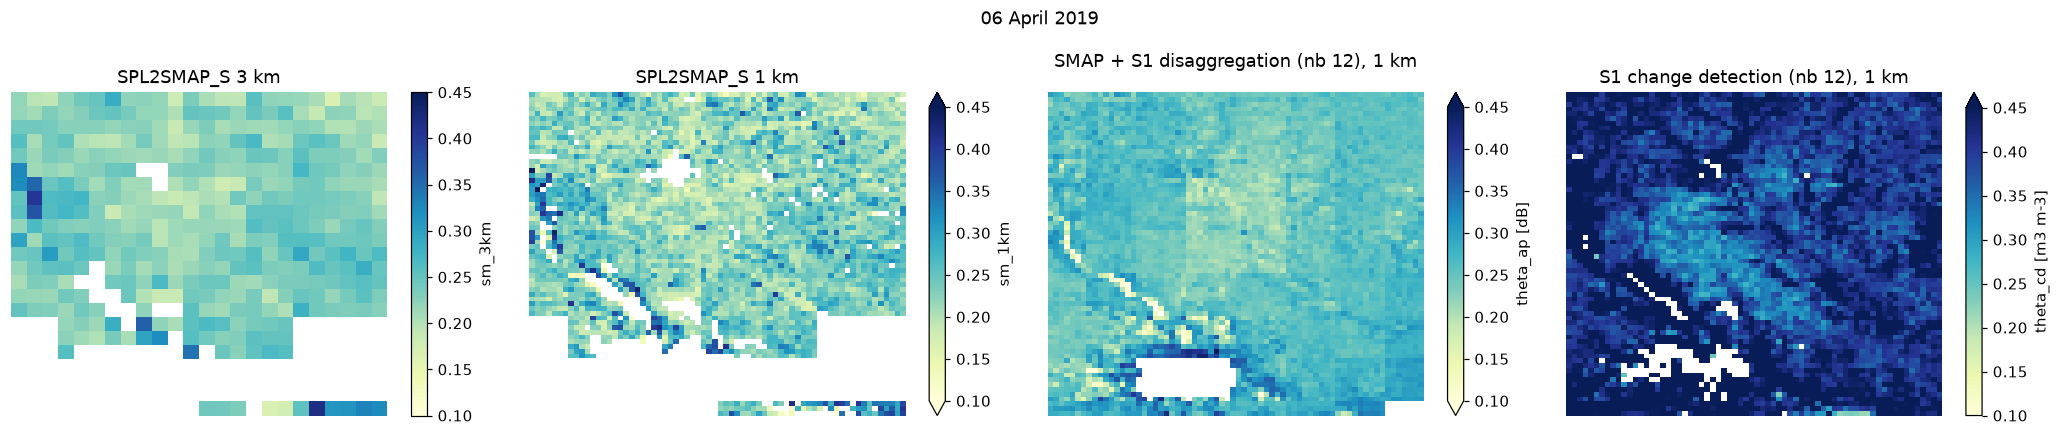

In [6]:
g1 = sm.ease2_grid("EASE2_M01km", aoi=sd.IOWA_SAR)  # 1 km EASE grid of the AOI
tmpl = xr.DataArray(np.zeros((g1.sizes["y"], g1.sizes["x"]), "float32"), coords={"y": g1.y, "x": g1.x}, dims=("y", "x")).rio.write_crs("EPSG:6933")  # template
own_t = pd.DatetimeIndex(own.time.values).normalize()  # notebook 12 dates
ap_t = pd.DatetimeIndex(ap.time.values).normalize()  # SPL2SMAP_S dates
common = sorted(set(own_t) & set(ap_t))  # same days
print(f"{len(common)} days with both")  # overlap
own_d = own.assign_coords(time=own_t).sel(time=common)  # own retrievals on common days
cd1 = sm.regrid(own_d.theta_cd, tmpl, method="average")  # change detection at 1 km
ap1 = sm.regrid(own_d.theta_ap, tmpl, method="average")  # SMAP disaggregation at 1 km
spl = ap.sm_1km.rename({"y_1km": "y", "x_1km": "x"}).assign_coords(time=ap_t).groupby("time").mean().sel(time=common)  # SPL2SMAP_S 1 km
spl = spl.assign_coords(x=tmpl.x, y=tmpl.y)  # same grid
day = common[int(np.argmax([float(spl.sel(time=d).notnull().mean()) for d in common]))]  # best covered common day
fig, ax = plt.subplots(1, 4, figsize=(19, 4))  # four maps
ap.sm_3km.assign_coords(time=ap_t).groupby("time").mean().sel(time=day).plot(ax=ax[0], cmap="YlGnBu", vmin=0.1, vmax=0.45); ax[0].set_title("SPL2SMAP_S 3 km")  # 3 km
spl.sel(time=day).plot(ax=ax[1], cmap="YlGnBu", vmin=0.1, vmax=0.45); ax[1].set_title("SPL2SMAP_S 1 km")  # 1 km
ap1.sel(time=day).plot(ax=ax[2], cmap="YlGnBu", vmin=0.1, vmax=0.45); ax[2].set_title("SMAP + S1 disaggregation (nb 12), 1 km")  # own AP
cd1.sel(time=day).plot(ax=ax[3], cmap="YlGnBu", vmin=0.1, vmax=0.45); ax[3].set_title("S1 change detection (nb 12), 1 km")  # own CD
for a in ax: a.axis("off")  # clean maps
plt.suptitle(f"{pd.Timestamp(day):%d %B %Y}"); plt.tight_layout(); plt.show()  # draw

## Agreement between the products

In [7]:
both = xr.Dataset({"SPL2SMAP_S": spl, "own disaggregation": ap1, "change detection": cd1})  # one dataset on the 1 km grid
pairs = [("SPL2SMAP_S", "own disaggregation"), ("SPL2SMAP_S", "change detection"), ("own disaggregation", "change detection")]  # comparisons
rows = []  # statistics
for a, b in pairs:  # each pair
    d = (both[a] - both[b]).values.ravel(); ok = np.isfinite(d)  # differences
    x, y = both[a].values.ravel()[ok], both[b].values.ravel()[ok]  # paired values
    rows.append({"pair": f"{a} vs {b}", "n": int(ok.sum()), "mean difference": float(d[ok].mean()), "ubRMSD": float(d[ok].std()),
                 "R (all cells and days)": float(np.corrcoef(x, y)[0, 1])})  # row
display(pd.DataFrame(rows).set_index("pair").round(3))  # table

,n,mean difference,ubRMSD,R (all cells and days)
pair,,,,
SPL2SMAP_S vs own disaggregation,22511,-0.011,0.055,0.755
SPL2SMAP_S vs change detection,25251,-0.174,0.072,0.680
own disaggregation vs change detection,62464,-0.185,0.063,0.666


## Validation at the stations

In [8]:
t6933 = Transformer.from_crs(4326, 6933, always_xy=True)  # to EASE coordinates
ins = {"USCRN Des Moines 17 E": sd.uscrn().sm_5.resample("1D").mean(), "SCAN Ames": sd.scan().sm_5}  # in situ 5 cm
prods = {"SPL2SMAP_S 1 km": spl, "SPL2SMAP_S 3 km": ap.sm_3km.rename({"y_3km": "y", "x_3km": "x"}).assign_coords(time=ap_t).groupby("time").mean(),
         "SMAP + S1 (nb 12), 1 km": ap1, "S1 change detection (nb 12), 1 km": cd1}  # products on EASE grids
rows = []  # metrics
for st, s in sd.STATIONS.iterrows():  # each station
    x, y = t6933.transform(s.lon, s.lat)  # station position
    for name, da in prods.items():  # each product
        px = da.sel(x=x, y=y, method="nearest").to_series().dropna()  # cell containing the station
        m = sm.validation_metrics(ins[st].reindex(px.index), px)  # metrics
        rows.append({"station": st, "product": name, "n": int(m.n), "bias": m.bias, "ubrmse": m.ubrmse, "R": m.pearson_r})  # row
display(pd.DataFrame(rows).set_index(["station", "product"]).round(3))  # table

n   bias  ubrmse  \
station               product                                                
USCRN Des Moines 17 E SPL2SMAP_S 1 km                     0    NaN     NaN   
                      SPL2SMAP_S 3 km                    18 -0.092   0.074   
                      SMAP + S1 (nb 12), 1 km            15 -0.090   0.043   
                      S1 change detection (nb 12), 1 km  15  0.121   0.063   
SCAN Ames             SPL2SMAP_S 1 km                     7 -0.019   0.063   
                      SPL2SMAP_S 3 km                    39 -0.048   0.075   
                      SMAP + S1 (nb 12), 1 km            12 -0.013   0.089   
                      S1 change detection (nb 12), 1 km  15  0.154   0.104   

                                                             R  
station               product                                   
USCRN Des Moines 17 E SPL2SMAP_S 1 km                      NaN  
                      SPL2SMAP_S 3 km                    0.424  
                      SMAP + S1 (nb 12), 1 km            0.815  
                      S1 change detection (nb 12), 1 km  0.758  
SCAN Ames             SPL2SMAP_S 1 km                    0.732  
                      SPL2SMAP_S 3 km                    0.658  
                      SMAP + S1 (nb 12), 1 km            0.385  
                      S1 change detection (nb 12), 1 km  0.418

## Summary and exercises

- SPL2SMAP_S granules carry EASE row and column indices, so they stack directly into 1 km and 3 km
  cubes; over central Iowa they exist about every 12 days in the growing season.
- Notebook 12's retrievals aggregated to 1 km can be compared with the operational product cell by
  cell on the same days.
- At 1 km the station comparison shows which approach carries the most information about point soil
  moisture; disaggregation products inherit the level and skill of SMAP.

**Exercises**

1. Repeat the comparison with the 3 km product and the notebook 12 retrievals aggregated to 3 km. Does
   the agreement improve?
2. Map the per-cell temporal correlation between SPL2SMAP_S 1 km and the change detection retrieval.
   Where do they disagree most, and what land cover is there?
3. Download a few CLMS 1 km SSM files for a European site with a free EU Login and read them with
   `sm.read_clms_ssm`.